# Uncertainty Propagation in Nerve Impulses Through the Action Potential Mechanism

__Aldemar Torres Valderrama__, CWI, Amsterdam, The Netherlands; Department of Neurology and Neurosurgery, Brain Center Rudolf Magnus, University Medical Center Utrecht, The Netherlands

__Jeroen Witteveen__, CWI, Amsterdam, The Netherlands

__Maria Navarro__, CWI, Amsterdam, The Netherlands

__Joke Blom__, CWI, Amsterdam, The Netherlands

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import active_subspaces as ac
import HH_model as hm
from generate_data import read_csv

SEED = 2015
t_start = time.perf_counter()

### Summary

Torres Valderrama et al. [[1]](https://doi.org/10.1186/2190-8567-5-3) propagate uncertainty in the 11 inputs of the Hodgkin–Huxley (H-H) model (four initial conditions, three conductances, three Nernst potentials and the membrane capacitance, each uniform with 20 % variability) to the membrane potential, and find with time-averaged Sobol indices that two inputs, $g_K$ and $E_{Na}$, carry most of the variance. Here we compute exact gradients of smooth scalar outputs of the same model by forward sensitivity equations and estimate their active subspaces from 1000 samples. The peak membrane potential of the oscillation shown in the paper's Fig. 1(a) has a one-dimensional active subspace dominated by $E_{Na}$ and $g_{Na}$, and averaged over the paper's time window the gradients single out the same two inputs as the paper, $g_K$ and $E_{Na}$.

### Active subspaces in brief

For a scalar function $f(\mathbf x)$ of $m$ normalized inputs $\mathbf x \in [-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$. The eigenvalue $\lambda_i$ is the mean squared directional derivative of $f$ along $\mathbf w_i$, so a gap after the first $n$ eigenvalues means that $f$ changes mostly along the $n$ active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a sufficient summary plot) shows that structure. We estimate $\mathbf C$ by the Monte Carlo average of $\nabla f\nabla f^T$ over samples and use the bootstrap to judge the eigenvalues and the subspace. See P. G. Constantine, [_Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]](https://doi.org/10.1137/1.9781611973860).

### The model

The H-H equations, [[1]](https://doi.org/10.1186/2190-8567-5-3) Eq. (1), for the membrane potential $v$ (mV, measured from rest, depolarization positive) and the gating variables $m$, $n$, $h$ are

$$
\begin{align}
C\frac{dv}{dt} &= -g_{Na}\, m^3 h\,(v - E_{Na}) - g_K\, n^4 (v - E_K) - g_L (v - E_L) + I,\\
\frac{dn}{dt} &= \frac{0.01(10-v)}{e^{(10-v)/10}-1}(1-n) - 0.125\, e^{-v/80}\, n,\\
\frac{dm}{dt} &= \frac{0.1(25-v)}{e^{(25-v)/10}-1}(1-m) - 4\, e^{-v/18}\, m,\\
\frac{dh}{dt} &= 0.07\, e^{-v/20}(1-h) - \frac{1}{e^{(30-v)/10}+1}\, h,
\end{align}
$$

with time in ms and the initial state $(v, m, n, h)(0) = (v_0, m_0, n_0, h_0)$. The 11 inputs are the vector $\xi$ of [[1]](https://doi.org/10.1186/2190-8567-5-3) Eq. (2), with the nominal values of its Table 2 (p. 6). They are independent and uniform with "20 % of variability in the nominal values" ([[1]](https://doi.org/10.1186/2190-8567-5-3) p. 3), which we read as nominal $\pm 20\,\%$.

**Settings the paper does not state.** These are our choices, recorded in `DATA.md`:

- **Injected current.** $I = 150\ \mu$A/cm² from $t = 0$. The paper does not give $I$ for Fig. 1; with this value the nominal trajectory matches Fig. 1(a) (checked below).
- **Time window.** We solve on $0 \le t \le 14$ ms; Fig. 1(a) shows 5–14 ms.
- **The current term.** Eq. (1) as printed adds $I$ to $dv/dt$ without dividing it by $C$. We use the H-H form above, $C\,dv/dt = \dots + I$. The two are the same at the nominal $C = 1$, but in the printed form $C$ becomes the most important input averaged over the window, contrary to the paper's Fig. 1(b) and Table 2, where $C$ is minor; the H-H form gives the paper's ranking (`DATA.md`; `HH_model.py` has both, `form="printed"`).
- **$h_0 > 1$.** Nominal $\pm 20\,\%$ lets $h_0$ reach 1.2, outside the physical range $[0, 1]$. We keep the paper's ranges; $h$ relaxes toward $h_\infty(v) < 1$ and the equations stay well defined.

**Quantities of interest.** The paper studies the time courses $v(t)$, $m(t)$, $n(t)$, $h(t)$ and defines no scalar output. At this current every sample fires one spike before 1 ms and then oscillates with decreasing amplitude, and Fig. 1(a) shows the second, smaller peak (its "acme", p. 3). We use

- $v_{\rm peak}$ (mV): the value of the second local maximum of $v(t)$, the acme of Fig. 1(a);
- $t_{\rm peak}$ (ms): its time;
- $v(t)$ at $t = 5, 5.5, \dots, 14$ ms, the time points of the paper's Fig. 1(a).

All three are smooth functions of the inputs in the box: no sample loses or gains a spike or a peak (checked below and in `DATA.md` for 2000 random points and all 2048 corners of the box). Peak value and time come from a `solve_ivp` event at $dv/dt = 0$. Their gradients come from the forward sensitivity equations solved with the model: $\partial v_{\rm peak}/\partial\xi = \partial v/\partial\xi$ at $t_{\rm peak}$, because $dv/dt = 0$ there, and $\partial t_{\rm peak}/\partial\xi = -\big(\tfrac{d}{dt}\partial v/\partial\xi\big)/v''$ at $t_{\rm peak}$.

The table of inputs below is built from `HH_model.py`.

In [2]:
source = {'n0': 'Table 2', 'm0': 'Table 2', 'h0': 'Table 2', 'v0': 'Table 2', 'gK': 'Table 2',
          'gNa': 'Table 2', 'gL': 'Table 2', 'EK': 'Table 2', 'ENa': 'Table 2', 'EL': 'Table 2',
          'C': 'Table 2'}
desc = {'n0': 'initial K activation', 'm0': 'initial Na activation', 'h0': 'initial Na inactivation',
        'v0': 'initial membrane potential', 'gK': 'max. K conductance', 'gNa': 'max. Na conductance',
        'gL': 'leak conductance', 'EK': 'K Nernst potential', 'ENa': 'Na Nernst potential',
        'EL': 'leak reversal potential', 'C': 'membrane capacitance'}
rows = ['| input | description | units | nominal | lower | upper | source |', '|---|---|---|---|---|---|---|']
for j, n in enumerate(hm.NAMES):
    rows.append(f'| `{n}` | {desc[n]} | {hm.UNITS[j]} | {hm.NOMINAL[j]:g} | {hm.LOWER[j]:.6g} | '
                f'{hm.UPPER[j]:.6g} | [1] {source[n]}, p. 6; range p. 3 |')
display(Markdown('\n'.join(rows)))
print(f'injected current I = {hm.I_INJ} uA/cm^2, form = {hm.FORM!r}, t in [0, {hm.T_END}] ms, '
      f'solver DOP853 rtol = {hm.RTOL:g}, atol = {hm.ATOL:g}')

| input | description | units | nominal | lower | upper | source |
|---|---|---|---|---|---|---|
| `n0` | initial K activation | - | 0.0003 | 0.00024 | 0.00036 | [1] Table 2, p. 6; range p. 3 |
| `m0` | initial Na activation | - | 0.0011 | 0.00088 | 0.00132 | [1] Table 2, p. 6; range p. 3 |
| `h0` | initial Na inactivation | - | 0.9998 | 0.79984 | 1.19976 | [1] Table 2, p. 6; range p. 3 |
| `v0` | initial membrane potential | mV | -10 | -12 | -8 | [1] Table 2, p. 6; range p. 3 |
| `gK` | max. K conductance | mS/cm^2 | 36 | 28.8 | 43.2 | [1] Table 2, p. 6; range p. 3 |
| `gNa` | max. Na conductance | mS/cm^2 | 120 | 96 | 144 | [1] Table 2, p. 6; range p. 3 |
| `gL` | leak conductance | mS/cm^2 | 0.3 | 0.24 | 0.36 | [1] Table 2, p. 6; range p. 3 |
| `EK` | K Nernst potential | mV | -12 | -14.4 | -9.6 | [1] Table 2, p. 6; range p. 3 |
| `ENa` | Na Nernst potential | mV | 115 | 92 | 138 | [1] Table 2, p. 6; range p. 3 |
| `EL` | leak reversal potential | mV | 10.613 | 8.4904 | 12.7356 | [1] Table 2, p. 6; range p. 3 |
| `C` | membrane capacitance | uF/cm^2 | 1 | 0.8 | 1.2 | [1] Table 2, p. 6; range p. 3 |

injected current I = 150.0 uA/cm^2, form = 'standard', t in [0, 14.0] ms, solver DOP853 rtol = 1e-10, atol = 1e-12


Table 2 prints the conductances in µS/cm²; the H-H values 36, 120 and 0.3 are in mS/cm² when $C$ is in µF/cm², $t$ in ms and $I$ in µA/cm², the units used here. The units do not affect the normalized inputs.

#### The nominal trajectory and Fig. 1(a)

We plot the nominal trajectory and 20 random ones on $[0, 14]$ ms, with the window of Fig. 1(a) shaded and the second maxima marked. Read from Fig. 1(a), the deterministic curve is near 5 mV at 5 ms, peaks near 45 mV at about 8.7 ms, has a trough near 10 mV at about 10.8 ms, and is near 30 mV at 14 ms.

nominal: v(5) = 6.5 mV, spike 117.1 mV at 0.60 ms, second peak 46.0 mV at 8.52 ms, trough 9.3 mV at 10.67 ms, v(14) = 30.2 mV


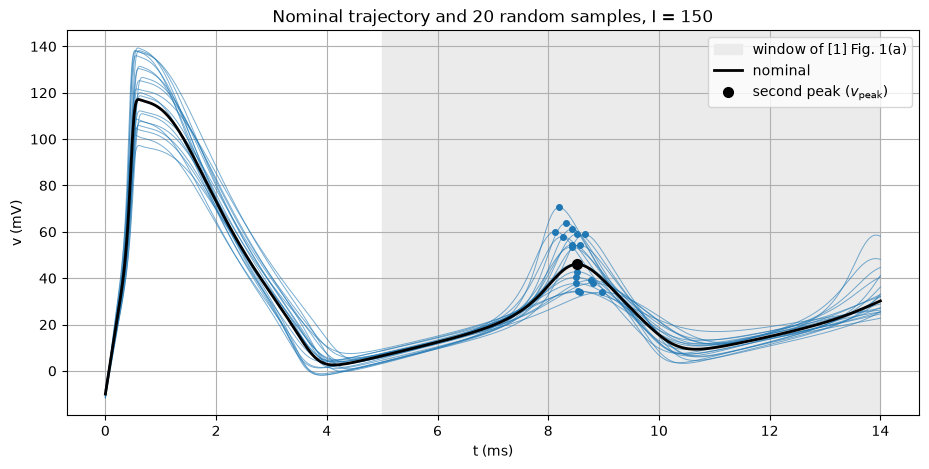

In [3]:
from scipy.integrate import solve_ivp

tt = np.linspace(0, hm.T_END, 1401)
nom = hm.trajectory(hm.NOMINAL, tt)
p = tuple(hm.NOMINAL)
def vmin(t, y, p, I, form):              # local minima of v, for the printout only
    return hm._rhs(t, y, p, I, form)[0]
vmin.direction = 1
tr = solve_ivp(hm._rhs, (0, hm.T_END), hm._y0(p), method='DOP853', args=(p, hm.I_INJ, hm.FORM),
               events=vmin, rtol=hm.RTOL, atol=hm.ATOL)
k_tr = np.flatnonzero(tr.t_events[0] > 9)[0]
print(f'nominal: v(5) = {nom.y[0][500]:.1f} mV, spike {nom.y_events[0][0, 0]:.1f} mV at {nom.t_events[0][0]:.2f} ms, '
      f'second peak {nom.y_events[0][1, 0]:.1f} mV at {nom.t_events[0][1]:.2f} ms, '
      f'trough {tr.y_events[0][k_tr, 0]:.1f} mV at {tr.t_events[0][k_tr]:.2f} ms, v(14) = {nom.y[0][-1]:.1f} mV')

space = ac.Uniform(hm.LOWER, hm.UPPER, names=list(hm.NAMES))
P20 = space.sample(20, rng=SEED)
fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(5, 14, color='0.92', label='window of [1] Fig. 1(a)')
for q in P20:
    s = hm.trajectory(q, tt)
    ax.plot(tt, s.y[0], color='C0', lw=0.7, alpha=0.6)
    ax.plot(s.t_events[0][1], s.y_events[0][1, 0], 'o', color='C0', ms=4)
ax.plot(tt, nom.y[0], 'k', lw=2, label='nominal')
ax.plot(nom.t_events[0][1], nom.y_events[0][1, 0], 'ko', ms=7, label=r'second peak ($v_{\rm peak}$)')
ax.set_xlabel('t (ms)'); ax.set_ylabel('v (mV)'); ax.grid(True); ax.legend(loc='upper right')
ax.set_title('Nominal trajectory and 20 random samples, I = 150')
plt.close(fig)
fig

The nominal trajectory has $v(5) = 6.5$ mV, its second peak 46.0 mV at 8.52 ms, its trough 9.3 mV at 10.67 ms and $v(14) = 30.2$ mV, close to the values read from Fig. 1(a) (about 5, 45 at 8.7, 10 at 10.8, and 30). `DATA.md` lists the same features for currents from 130 to 170 µA/cm²: the figure fixes $I$ to roughly $\pm 10$ µA/cm², and much smaller currents give a second full spike rather than the damped oscillation of Fig. 1(a). Every random sample shows the same pattern, one spike before 1 ms and a smaller second peak inside the window.

### Load the data

`generate_data.py` drew 1000 samples from the uniform box with `numpy.random.default_rng(2015)` and solved the model with its sensitivities for each one (2 minutes on two processes; `DATA.md`). The gradients in `gradients.csv` are with respect to the physical inputs; column `11*i + j` is the derivative of output `i` with respect to input `j`.

In [4]:
X = read_csv('inputs.csv')                                   # (1000, 11) physical inputs
F = read_csv('outputs.csv')                                  # (1000, 21) vpeak, tpeak, v(5..14)
G = read_csv('gradients.csv').reshape(len(X), F.shape[1], X.shape[1])   # physical gradients
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}; outputs: {", ".join(hm.QOI_NAMES[:4])}, ..., {hm.QOI_NAMES[-1]}')

inputs (1000, 11), outputs (1000, 21), gradients (1000, 21, 11); outputs: vpeak, tpeak, v(5), v(5.5), ..., v(14)


We re-solve three samples with `HH_model.py` and compare with the stored outputs and gradients, and print the range of the two peak outputs over the 1000 samples.

In [5]:
for r in [0, 1, 2]:
    f_r, g_r = hm.qoi_and_grad(X[r])
    print(f'sample {r}: max relative difference, outputs {np.max(np.abs(f_r - F[r]) / np.abs(F[r])):.1e}, '
          f'gradients {np.max(np.linalg.norm(g_r - G[r], axis=1) / np.linalg.norm(G[r], axis=1)):.1e}')
print(f'vpeak: {F[:, 0].min():.1f} to {F[:, 0].max():.1f} mV; tpeak: {F[:, 1].min():.2f} to {F[:, 1].max():.2f} ms')

sample 0: max relative difference, outputs 2.6e-13, gradients 1.6e-11


sample 1: max relative difference, outputs 2.5e-13, gradients 2.3e-11


sample 2: max relative difference, outputs 3.2e-13, gradients 2.7e-11
vpeak: 21.7 to 73.6 mV; tpeak: 7.89 to 9.16 ms


The model reproduces the stored outputs to the 13 significant digits written (relative differences up to 3.2e-13; gradients 2.7e-11). Over the 1000 samples $v_{\rm peak}$ ranges from 21.7 to 73.6 mV and $t_{\rm peak}$ from 7.89 to 9.16 ms, so the second peak always lies well inside the window (the third maximum, where one occurs, comes after 13.2 ms; `DATA.md`).

### Estimate the active subspace of the peak potential

The model is cheap and smooth and its gradients are exact to about $10^{-9}$ (`DATA.md`), so we use the gradient estimator (`estimator="as"`): $\hat{\mathbf C} = \frac1N\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, from $N = 1000$ samples, about 90 per input. We pass physical inputs and physical gradients with the space, and v1 normalizes them. The bootstrap uses 500 replicates. We orient $\mathbf w_1$ so that $v_{\rm peak}$ increases along it.

In [6]:
names = list(hm.NAMES)
labels = [r'$n_0$', r'$m_0$', r'$h_0$', r'$v_0$', r'$g_K$', r'$g_{Na}$', r'$g_L$', r'$E_K$',
          r'$E_{Na}$', r'$E_L$', r'$C$']
XX = space.to_normalized(X)

sub = ac.active_subspace(space=space, X=X, f=F[:, 0], grads=G[:, 0], estimator='as',
                         nboot=500, bootstrap_vectors=2, rng=SEED, qoi='vpeak')
sub = ac.orient(sub, by='covariance', X=X, f=F[:, 0], columns=2)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
print('eigenvalues:', np.array2string(lam, precision=3, max_line_width=120))
print(f'lambda1/lambda2 = {lam[0] / lam[1]:.0f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}; '
      f'eigenvalue-gap rule: n = {sub.n}')
print(f'fraction of trace in lambda1: {lam[0] / lam.sum():.3f}')

eigenvalues: [3.300e+02 2.895e+00 2.247e+00 5.335e-02 4.996e-02 4.478e-03 3.207e-04 1.859e-04 1.092e-07 9.344e-11 6.481e-11]
lambda1/lambda2 = 114, lambda2/lambda3 = 1.29; eigenvalue-gap rule: n = 1
fraction of trace in lambda1: 0.984


### Results for $v_{\rm peak}$

#### Eigenvalues

95% bootstrap intervals: lambda1 [324.74, 335.45], lambda2 [2.682, 3.129]


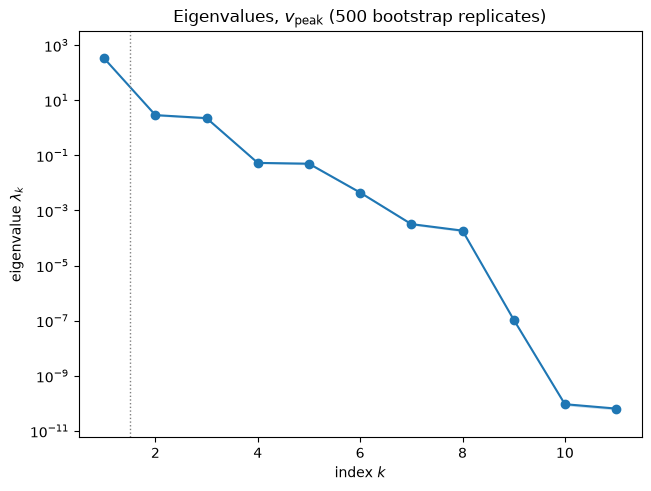

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
ax.set_title(r'Eigenvalues, $v_{\rm peak}$ (500 bootstrap replicates)')
lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, :2], [2.5, 97.5], axis=0)
print(f'95% bootstrap intervals: lambda1 [{lo[0]:.2f}, {hi[0]:.2f}], lambda2 [{lo[1]:.3f}, {hi[1]:.3f}]')
fig

The first eigenvalue, $\lambda_1 = 330$, is 114 times $\lambda_2 = 2.9$ and holds 98.4 % of the trace. Their 95 % bootstrap intervals, [324.74, 335.45] and [2.682, 3.129], are far apart, and the eigenvalue-gap rule picks $n = 1$. The next two eigenvalues are close to each other ($\lambda_2/\lambda_3 = 1.29$).

#### Subspace errors

mean bootstrap subspace distance: n = 1: 0.004, n = 2: 0.072, n = 3: 0.008


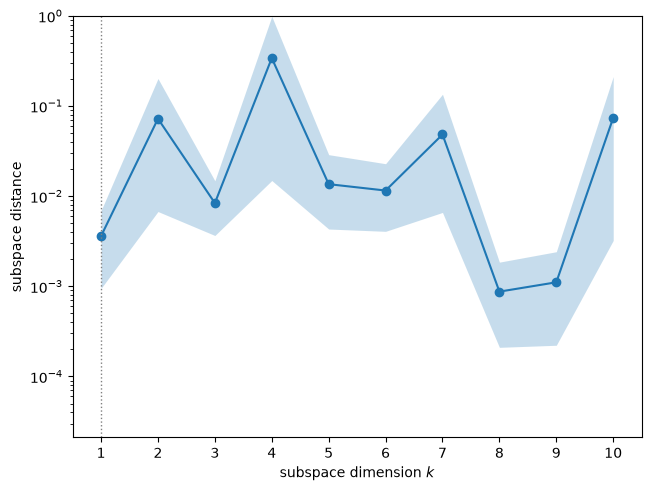

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
d = sub.bootstrap_distances.mean(axis=0)
print(f'mean bootstrap subspace distance: n = 1: {d[0]:.3f}, n = 2: {d[1]:.3f}, n = 3: {d[2]:.3f}')
fig

The mean bootstrap distance of the one-dimensional subspace is 0.004, so $\mathbf w_1$ is well determined. For $n = 2$ it is 0.072, because $\lambda_2$ and $\lambda_3$ are nearly equal and the second direction alone is poorly determined; the three-dimensional subspace is again stable (0.008).

#### Eigenvectors

w1: ENa +0.869, gNa +0.443, EK -0.175, gK -0.097, h0 +0.087, gL -0.018, C -0.015, EL -0.006, v0 -0.000, n0 +0.000, m0 +0.000
|w1| < 0.01 for: n0, m0, v0, EL


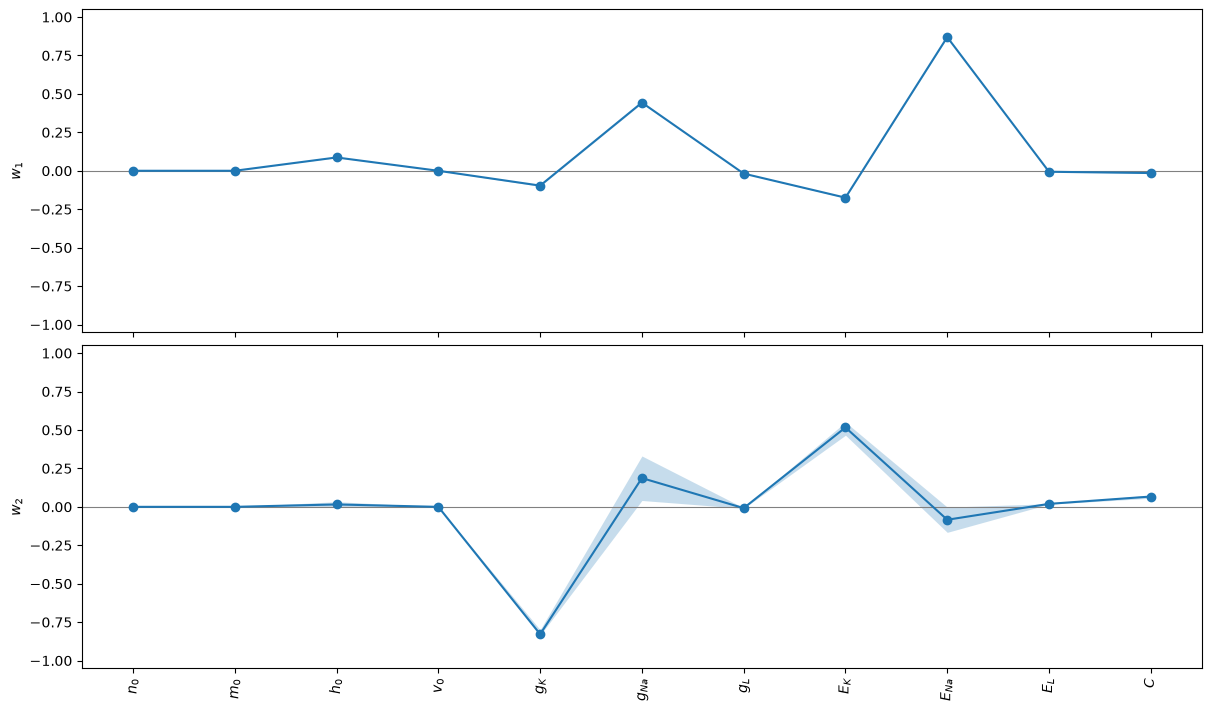

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile',
                                          figsize=(12, 7))
w1 = sub.W[:, 0]
order = np.argsort(-np.abs(w1))
print('w1:', ', '.join(f'{names[j]} {w1[j]:+.3f}' for j in order))
print(f'|w1| < 0.01 for: {", ".join(names[j] for j in range(11) if abs(w1[j]) < 0.01)}')
fig

$\mathbf w_1$ is dominated by $E_{Na}$ (+0.869) and $g_{Na}$ (+0.443), with smaller weights on $E_K$ (−0.175), $g_K$ (−0.097) and $h_0$ (+0.087): the acme rises with the sodium drive. The initial conditions $n_0$, $m_0$, $v_0$ and the leak potential $E_L$ have $|w_1| < 0.01$, and $C$ only −0.015. The initial state is forgotten after the first spike, as in the paper, where $n_0$, $m_0$ and $v_0$ have negligible Sobol indices.

#### Sufficient summary plot

corr(w1^T x, vpeak) = 0.9933


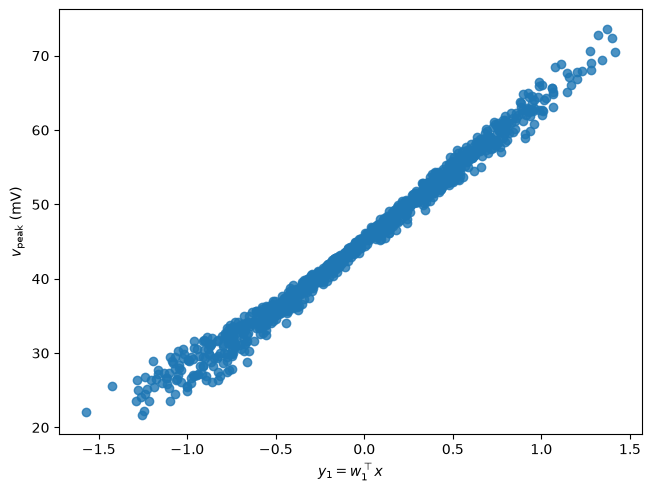

In [10]:
y1 = XX @ w1
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 0], dims=1, qoi_label=r'$v_{\rm peak}$ (mV)')
print(f'corr(w1^T x, vpeak) = {np.corrcoef(y1, F[:, 0])[0, 1]:.4f}')
fig

The summary plot shows a tight, nearly linear trend: the correlation between $\mathbf w_1^T\mathbf x$ and $v_{\rm peak}$ is 0.9933. The scatter about the trend is the small variation along the other directions ($\lambda_2 + \lambda_3 + \dots$ is 1.6 % of the trace).

#### No threshold along the active direction

A spike threshold would show as a jump in $v_{\rm peak}$. We walk through the center of the box along $\mathbf w_1$, as far as the box allows, at 81 points, and check that every point has the same pattern of maxima (one spike before 2 ms, the second peak between 5 and 12 ms; `HH_model.qoi` raises an error otherwise).

81 points, w1^T x from -1.15 to 1.15: vpeak from 26.5 to 67.3 mV; largest |second difference| 0.014 mV (step 0.029)


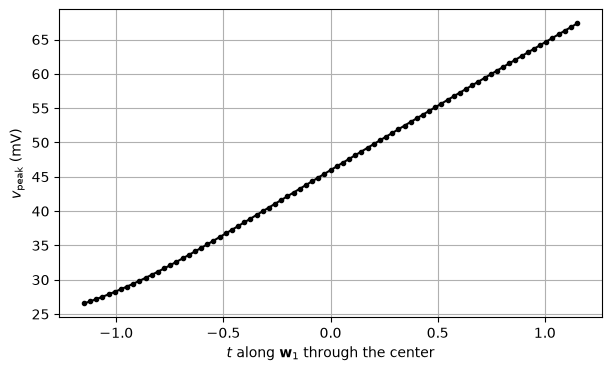

In [11]:
tmax = 1 / np.max(np.abs(w1))
ts = np.linspace(-tmax, tmax, 81)
Pline = space.from_normalized(np.outer(ts, w1))
vline = np.array([hm.qoi(q)[0] for q in Pline])
d2 = np.abs(np.diff(vline, 2))
print(f'{len(ts)} points, w1^T x from {-tmax:.2f} to {tmax:.2f}: vpeak from {vline.min():.1f} to {vline.max():.1f} mV; '
      f'largest |second difference| {d2.max():.3f} mV (step {ts[1] - ts[0]:.3f})')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ts, vline, 'k.-')
ax.set_xlabel(r'$t$ along $\mathbf{w}_1$ through the center'); ax.set_ylabel(r'$v_{\rm peak}$ (mV)'); ax.grid(True)
plt.close(fig)
fig

Along the line, $v_{\rm peak}$ increases smoothly from 26.5 to 67.3 mV; the largest second difference is 0.014 mV at a step of 0.029, so there is no jump. With the 1000 samples here and the 2000 random points and 2048 corners checked in `DATA.md`, this shows that no sample crosses a firing threshold at this current: the second peak is a graded damped oscillation, not an all-or-none spike.

#### A one-dimensional surrogate

We fit polynomials in $y_1 = \mathbf w_1^T\mathbf x$ to the 1000 samples and report the leave-one-out $R^2$.

degree 1: LOO R^2 = 0.9865
degree 2: LOO R^2 = 0.9881
degree 3: LOO R^2 = 0.9889
degree 3: RMS residual 1.10 mV, max |residual| 4.29 mV


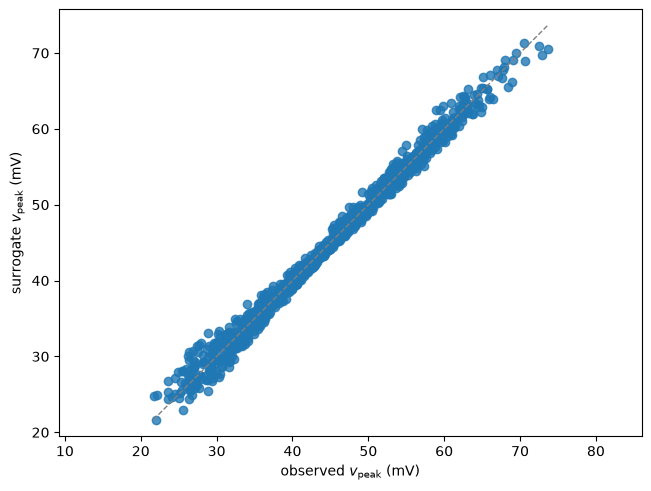

In [12]:
sub1 = ac.with_dimension(sub, 1)
for deg in [1, 2, 3]:
    srg = ac.fit_surrogate(X=X, f=F[:, 0], space=space, subspace=sub1, kind='poly', degree=deg)
    print(f'degree {deg}: LOO R^2 = {srg.loo_r_squared:.4f}')
srg = ac.fit_surrogate(X=X, f=F[:, 0], space=space, subspace=sub1, kind='poly', degree=3)
res = F[:, 0] - srg.evaluate(XX @ sub1.W1)
print(f'degree 3: RMS residual {np.sqrt(np.mean(res**2)):.2f} mV, max |residual| {np.abs(res).max():.2f} mV')
fig, ax = ac.plotting.plot_surrogate_fit(srg, X=X, f=F[:, 0], qoi_label=r'$v_{\rm peak}$ (mV)')
fig

A linear function of $y_1$ already has a leave-one-out $R^2$ of 0.9865; the cubic reaches 0.9889, with an RMS residual of 1.10 mV (maximum 4.29 mV) on outputs that range from 21.7 to 73.6 mV. One active variable is enough for a good surrogate of the peak potential.

### The time of the peak

The same estimator for $t_{\rm peak}$.

eigenvalues: [1.5004e-01 3.3128e-02 1.3099e-03 6.1803e-04 1.2724e-04] ...
lambda1/lambda2 = 4.53, lambda2/lambda3 = 25.3; eigenvalue-gap rule: n = 1
w1: gK +0.71, ENa -0.42, C +0.39, h0 +0.35, gNa -0.20
w2: ENa +0.73, gNa +0.47, h0 +0.31, gK +0.29, C +0.24
1-D polynomial degree 3: LOO R^2 = 0.9333
2-D polynomial degree 2: LOO R^2 = 0.9563
2-D polynomial degree 3: LOO R^2 = 0.9852


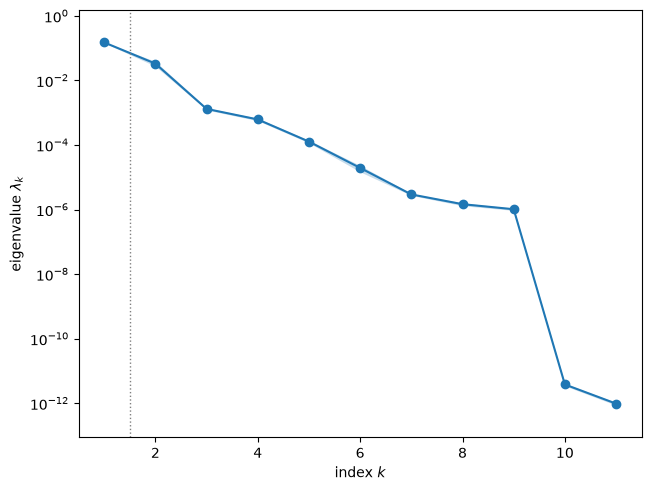

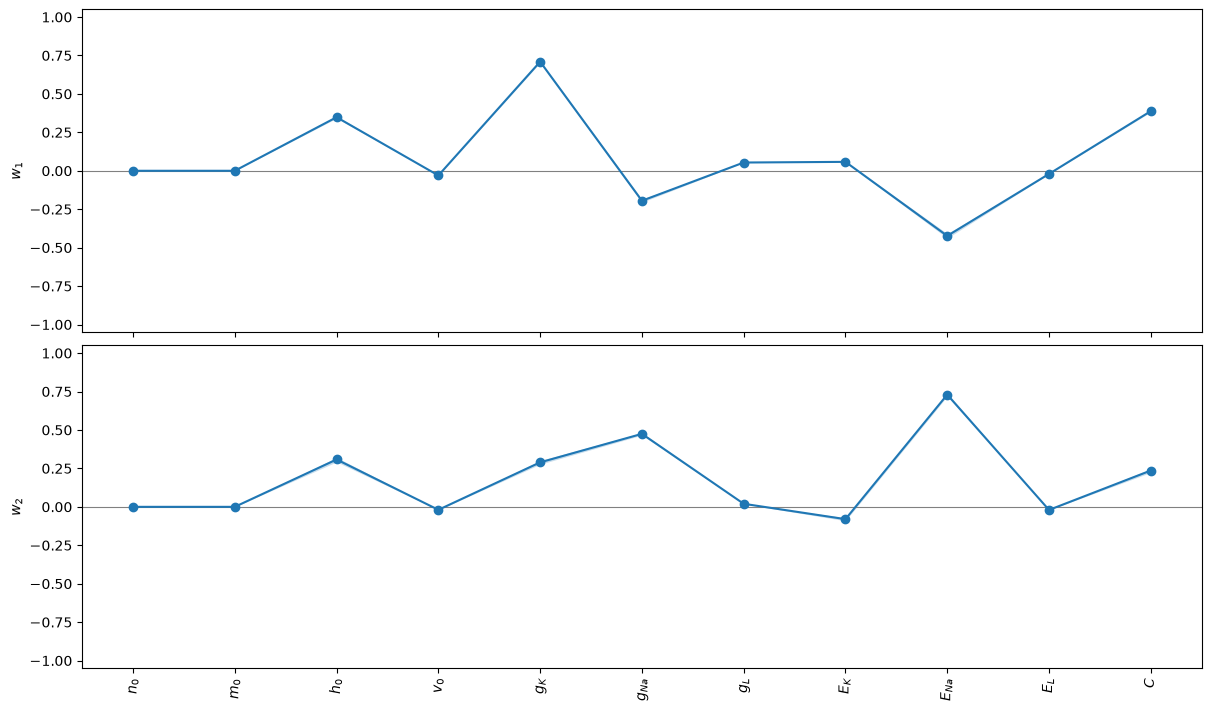

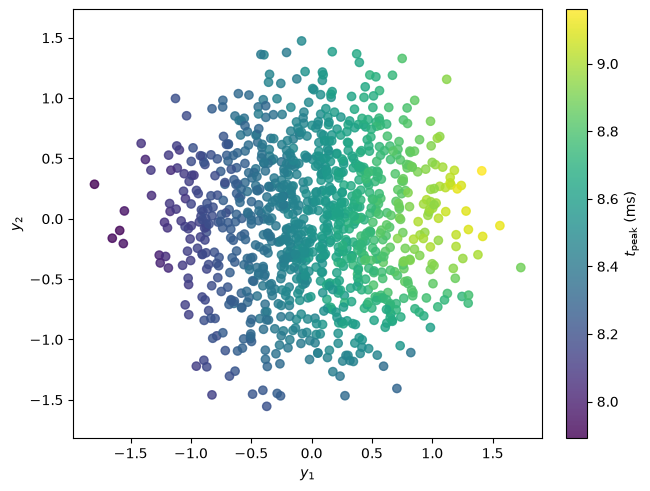

In [13]:
subt = ac.active_subspace(space=space, X=X, f=F[:, 1], grads=G[:, 1], estimator='as',
                          nboot=500, bootstrap_vectors=2, rng=SEED, qoi='tpeak')
subt = ac.orient(subt, by='covariance', X=X, f=F[:, 1], columns=2)
lt = subt.eigenvalues
print('eigenvalues:', np.array2string(lt[:5], precision=4), '...')
print(f'lambda1/lambda2 = {lt[0] / lt[1]:.2f}, lambda2/lambda3 = {lt[1] / lt[2]:.1f}; eigenvalue-gap rule: n = {subt.n}')
for i in range(2):
    w = subt.W[:, i]
    print(f'w{i + 1}:', ', '.join(f'{names[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:5]))
srg_t1 = ac.fit_surrogate(X=X, f=F[:, 1], space=space, subspace=ac.with_dimension(subt, 1), kind='poly', degree=3)
print(f'1-D polynomial degree 3: LOO R^2 = {srg_t1.loo_r_squared:.4f}')
subt2 = ac.with_dimension(subt, 2)
for deg in [2, 3]:
    srg_t = ac.fit_surrogate(X=X, f=F[:, 1], space=space, subspace=subt2, kind='poly', degree=deg)
    print(f'2-D polynomial degree {deg}: LOO R^2 = {srg_t.loo_r_squared:.4f}')
fig1, _ = ac.plotting.plot_eigenvalues(subt)
fig2, _ = ac.plotting.plot_eigenvectors(subt2, indices=[0, 1], labels=labels, interval='percentile', figsize=(12, 7))
display(fig1, fig2)
plt.close(fig1); plt.close(fig2)
fig, ax = ac.plotting.plot_sufficient_summary(subt2, X=X, f=F[:, 1], dims=2, qoi_label=r'$t_{\rm peak}$ (ms)')
fig

For $t_{\rm peak}$, $\lambda_1/\lambda_2 = 4.53$ and $\lambda_2/\lambda_3 = 25.3$. The gap rule takes $n = 1$ at the first ratio, but the larger second gap points to two dimensions, and the surrogates agree: a cubic in one active variable has LOO $R^2$ = 0.9333, a cubic in two has 0.9852. The first direction is mostly potassium and capacitance ($g_K$ +0.71, $E_{Na}$ −0.42, $C$ +0.39, $h_0$ +0.35); the second is mostly sodium ($E_{Na}$ +0.73, $g_{Na}$ +0.47).

### The membrane potential over the window of Fig. 1(a)

The paper's Sobol indices are functions of time (Fig. 1(a), middle), and its Fig. 1(b) and Table 2 rank the inputs by their indices averaged over the window. We compute the active subspace of $v(t)$ at each of the 19 times, and then two averages over the window: the normalized activity scores $a_j(t) = \sum_i \lambda_i(t) w_{ji}(t)^2 = \mathbb E[(\partial v(t)/\partial x_j)^2]$, divided by their sum at each time and then averaged (the same averaging as the paper's Sobol indices), and the eigenvalues of the time-averaged matrix $\bar{\mathbf C} = \frac{1}{19}\sum_t \mathbf C(t)$.

  t (ms)  lambda1/lambda2  n  corr(y1,v)  w1, largest 3
    5.0       142.9      1  -0.997      ENa +0.64, gNa +0.41, EK -0.40
    5.5       172.5      1  -0.998      ENa +0.63, gNa +0.42, h0 +0.39
    6.0       179.3      1  -0.997      ENa +0.59, gK +0.46, h0 +0.40
    6.5        84.9      1  -0.994      gK +0.60, ENa +0.48, h0 +0.43
    7.0        22.5      1  -0.980      gK +0.77, h0 +0.46, C +0.30
    7.5        11.5      1  -0.943      gK +0.78, h0 +0.42, C +0.35
    8.0        12.2      1  -0.958      ENa -0.69, gK +0.52, gNa -0.35
    8.5        10.0      1  -0.960      ENa -0.86, gNa -0.45, gK +0.16
    9.0         3.3      1  -0.899      ENa -0.78, gNa -0.43, h0 -0.31
    9.5         2.2      1  -0.894      gK -0.57, C -0.57, h0 -0.56
   10.0         7.6      1  -0.944      ENa +0.67, C -0.46, EK -0.38
   10.5         8.8      1  -0.965      ENa +0.80, EK -0.43, gNa +0.34
   11.0         9.4      1  -0.969      ENa +0.72, gK +0.43, EK -0.38
   11.5         9.7      1  -0.979 

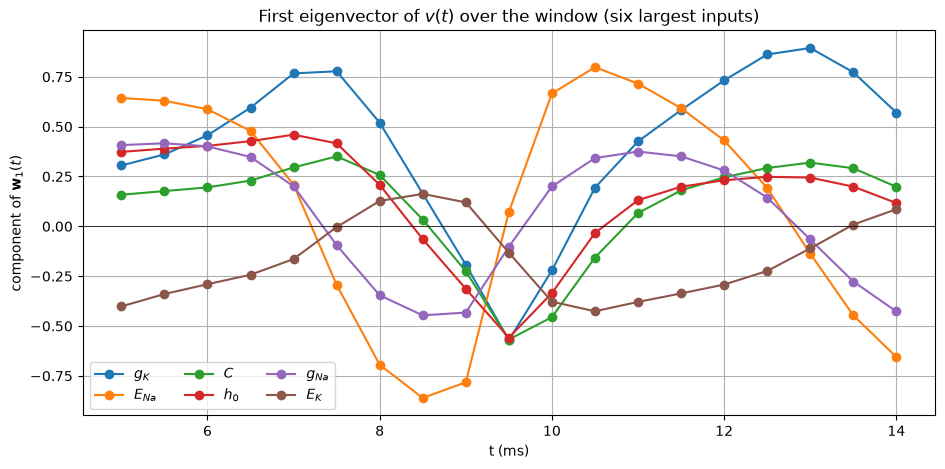

In [14]:
times = hm.TIMES
Gn = G[:, 2:] * (hm.UPPER - hm.LOWER) / 2       # gradients w.r.t. normalized inputs
W1t, ratios, prev = [], [], sub
print('  t (ms)  lambda1/lambda2  n  corr(y1,v)  w1, largest 3')
for k, t in enumerate(times):
    s = ac.active_subspace(space=space, grads=G[:, 2 + k], estimator='as')
    s = ac.orient(s, by='reference', reference=prev, columns=1)
    prev = s
    w = s.W[:, 0]
    W1t.append(w); ratios.append(s.eigenvalues[0] / s.eigenvalues[1])
    c = np.corrcoef(XX @ w, F[:, 2 + k])[0, 1]
    print(f'  {t:5.1f}  {ratios[-1]:10.1f}      {s.n}  {c:+.3f}      '
          + ', '.join(f'{names[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:3]))
W1t = np.array(W1t)

A = (Gn**2).mean(axis=0)                     # (19, 11) activity scores at each time
S = (A / A.sum(axis=1, keepdims=True)).mean(axis=0)
Cbar = np.einsum('itj,itk->jk', Gn, Gn) / (Gn.shape[0] * Gn.shape[1])
lb, Wb = np.linalg.eigh(Cbar)
lb, Wb = lb[::-1], Wb[:, ::-1]
print('\ntime-averaged normalized activity scores, scaled to max 1:')
print(', '.join(f'{names[j]} {S[j] / S.max():.3f}' for j in np.argsort(-S)))
print(f'eigenvalues of Cbar: {np.array2string(lb[:5], precision=3)} ...; '
      f'lambda1/lambda2 = {lb[0] / lb[1]:.2f}, lambda2/lambda3 = {lb[1] / lb[2]:.1f}; '
      f'(lambda1 + lambda2)/trace = {(lb[0] + lb[1]) / lb.sum():.3f}')
for i in range(2):
    print(f'Cbar w{i + 1}:', ', '.join(f'{names[j]} {Wb[j, i]:+.2f}' for j in np.argsort(-np.abs(Wb[:, i]))[:4]))

fig, ax = plt.subplots(figsize=(11, 5))
for j in np.argsort(-np.abs(W1t).max(axis=0))[:6]:
    ax.plot(times, W1t[:, j], 'o-', label=labels[j])
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('t (ms)'); ax.set_ylabel(r'component of $\mathbf{w}_1(t)$'); ax.grid(True)
ax.set_title(r'First eigenvector of $v(t)$ over the window (six largest inputs)')
ax.legend(ncol=3)
plt.close(fig)
fig

At each of the 19 times the gap rule picks $n = 1$, with $\lambda_1/\lambda_2$ between 2.2 (at 9.5 ms, as $v$ falls after the peak) and 179.3 (at 6 ms), and $|{\rm corr}(y_1, v)| \ge 0.894$. The leading inputs alternate as in the paper's time-resolved Sobol indices (Fig. 1(a), middle, where $g_K$ peaks near 7.3 and 13 ms and $E_{Na}$ near 8.5 and 10.7 ms): here $g_K$ leads at 6.5–7.5 ms and 12–13.5 ms, and $E_{Na}$ at 8–9 ms and 10–11.5 ms.

Averaged over the window, the normalized activity scores rank $g_K$ (1.000) and $E_{Na}$ (0.993) first, well ahead of $g_{Na}$ (0.322), $h_0$ (0.292), $C$ (0.216) and $E_K$ (0.199), while $n_0$, $m_0$, $v_0$, $g_L$ and $E_L$ are at most 0.003: the same two dominant inputs and the same five negligible ones as the paper's Table 2. The time-averaged matrix $\bar{\mathbf C}$ has two large eigenvalues (48.3 and 23.4, then 2.86; $\lambda_2/\lambda_3 = 8.2$) that hold 0.953 of its trace. Its first eigenvector is mostly $E_{Na}$ and $g_{Na}$ (−0.79, −0.41, with $g_K$ +0.38), the second mostly $g_K$ (+0.73): over the window, $v(t)$ varies mostly in a two-dimensional subspace, which corresponds to the paper's model with two uncertain inputs, $g_K$ and $E_{Na}$.

### Comparison with the paper

The paper has no active subspace. It reports Sobol indices, the SVD of the time-averaged Sobol matrix (Table 2) and box plots of $v(t)$ (Fig. 1(a)). The table compares what can be compared; "not reported" marks quantities the paper does not give. Values read from figures are approximate.

In [15]:
paper_mode1 = {'gK': 1.000000, 'ENa': 0.532895, 'EK': 0.232445, 'gNa': 0.172271, 'h0': 0.140569,
               'C': 0.099635}
Sn = S / S.max()
rows = ['| quantity | paper [1] | this notebook |', '|---|---|---|',
        f'| nominal $v$ at 5 ms (mV) | about 5 (Fig. 1(a), read) | {nom.y[0][500]:.1f} |',
        f'| nominal second peak (mV, ms) | about 45 at about 8.7 (Fig. 1(a), read) | '
        f'{nom.y_events[0][1, 0]:.1f} at {nom.t_events[0][1]:.2f} |',
        f'| nominal trough (mV, ms) | about 10 at about 10.8 (Fig. 1(a), read) | '
        f'{tr.y_events[0][k_tr, 0]:.1f} at {tr.t_events[0][k_tr]:.2f} |',
        '| injected current $I$ | not reported | 150 µA/cm² (chosen to match Fig. 1(a)) |',
        f'| two most important inputs, averaged over 5–14 ms | $g_K$, $E_{{Na}}$ (Fig. 1(b), Table 2 mode 1) | '
        f'{", ".join(names[j] for j in np.argsort(-S)[:2])} (normalized activity scores) |']
for n in ['gK', 'ENa', 'EK', 'gNa', 'h0', 'C']:
    rows.append(f'| weight of `{n}`, scaled to max 1 | {paper_mode1[n]:.3f} (Table 2 mode 1, Sobol, $v,n,m,h$) | '
                f'{Sn[names.index(n)]:.3f} (activity, $v$ only) |')
rows += ['| inputs with negligible weight | $n_0$, $m_0$, $v_0$, $g_L$, $E_L$ (Table 2 mode 1 < 0.002) | '
         + ', '.join(names[j] for j in range(11) if Sn[j] < 0.005) + ' (< 0.005) |',
         f'| energy of leading mode(s) | mode 1: 0.945 (Table 2) | $\\bar{{\\mathbf C}}$: '
         f'$\\lambda_1/\\mathrm{{tr}}$ = {lb[0] / lb.sum():.3f}, $(\\lambda_1+\\lambda_2)/\\mathrm{{tr}}$ = {(lb[0] + lb[1]) / lb.sum():.3f} |',
         f'| $v_{{\\rm peak}}$: $\\lambda_1/\\lambda_2$, dimension | not reported | {lam[0] / lam[1]:.0f}, n = {sub.n} |',
         f'| $v_{{\\rm peak}}$: leading inputs | $E_{{Na}}$ largest Sobol index near the peak (Fig. 1(a), read) | '
         + ', '.join(f'{names[j]} {w1[j]:+.2f}' for j in order[:2]) + ' |',
         f'| $v_{{\\rm peak}}$: LOO $R^2$, cubic in $y_1$ | not reported | {srg.loo_r_squared:.4f} |']
display(Markdown('\n'.join(rows)))
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

| quantity | paper [1] | this notebook |
|---|---|---|
| nominal $v$ at 5 ms (mV) | about 5 (Fig. 1(a), read) | 6.5 |
| nominal second peak (mV, ms) | about 45 at about 8.7 (Fig. 1(a), read) | 46.0 at 8.52 |
| nominal trough (mV, ms) | about 10 at about 10.8 (Fig. 1(a), read) | 9.3 at 10.67 |
| injected current $I$ | not reported | 150 µA/cm² (chosen to match Fig. 1(a)) |
| two most important inputs, averaged over 5–14 ms | $g_K$, $E_{Na}$ (Fig. 1(b), Table 2 mode 1) | gK, ENa (normalized activity scores) |
| weight of `gK`, scaled to max 1 | 1.000 (Table 2 mode 1, Sobol, $v,n,m,h$) | 1.000 (activity, $v$ only) |
| weight of `ENa`, scaled to max 1 | 0.533 (Table 2 mode 1, Sobol, $v,n,m,h$) | 0.993 (activity, $v$ only) |
| weight of `EK`, scaled to max 1 | 0.232 (Table 2 mode 1, Sobol, $v,n,m,h$) | 0.199 (activity, $v$ only) |
| weight of `gNa`, scaled to max 1 | 0.172 (Table 2 mode 1, Sobol, $v,n,m,h$) | 0.322 (activity, $v$ only) |
| weight of `h0`, scaled to max 1 | 0.141 (Table 2 mode 1, Sobol, $v,n,m,h$) | 0.292 (activity, $v$ only) |
| weight of `C`, scaled to max 1 | 0.100 (Table 2 mode 1, Sobol, $v,n,m,h$) | 0.216 (activity, $v$ only) |
| inputs with negligible weight | $n_0$, $m_0$, $v_0$, $g_L$, $E_L$ (Table 2 mode 1 < 0.002) | n0, m0, v0, gL, EL (< 0.005) |
| energy of leading mode(s) | mode 1: 0.945 (Table 2) | $\bar{\mathbf C}$: $\lambda_1/\mathrm{tr}$ = 0.642, $(\lambda_1+\lambda_2)/\mathrm{tr}$ = 0.953 |
| $v_{\rm peak}$: $\lambda_1/\lambda_2$, dimension | not reported | 114, n = 1 |
| $v_{\rm peak}$: leading inputs | $E_{Na}$ largest Sobol index near the peak (Fig. 1(a), read) | ENa +0.87, gNa +0.44 |
| $v_{\rm peak}$: LOO $R^2$, cubic in $y_1$ | not reported | 0.9889 |

Total run time: 11 s


With $I = 150$ µA/cm², the nominal curve matches Fig. 1(a) to reading precision, and the gradients single out $g_K$ and $E_{Na}$ as the paper's Sobol indices do, with the same negligible inputs. The relative weights differ ($E_{Na}$ 0.993 here against 0.533 in Table 2, and $g_{Na}$, $h_0$ and $C$ about twice as large here). The two rankings measure different things: the paper's mode 1 is the leading singular vector of first-order Sobol indices averaged over time for all four outputs $v, n, m, h$, from a sparse-grid interpolant, while ours are mean squared derivatives of $v$ alone. With the current term as printed in Eq. (1), not divided by $C$, $C$ would rank first (`DATA.md`), which is why we use the H-H form. The numbers in this notebook are not a reproduction of the paper's computation: the paper reports no scalar output, no gradients and no samples.

### References

[[1]][R1] A. Torres Valderrama, J. Witteveen, M. Navarro and J. Blom. _Uncertainty propagation in nerve impulses through the action potential mechanism_. The Journal of Mathematical Neuroscience, 5:3, 2015. doi:10.1186/2190-8567-5-3

[[2]][R2] P. G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, Philadelphia, 2015. doi:10.1137/1.9781611973860

[[3]][R3] A. L. Hodgkin and A. F. Huxley. _A quantitative description of membrane current and its application to conduction and excitation in nerve_. The Journal of Physiology, 117(4):500–544, 1952. doi:10.1113/jphysiol.1952.sp004764

[R1]: https://doi.org/10.1186/2190-8567-5-3
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1113/jphysiol.1952.sp004764

### Acknowledgments

From [[1]][R1]: the work was supported by the European Commission's 7th Framework Program BioPreDyn grant number 289434, and A. Torres Valderrama by the Exact Sciences division of the Netherlands Organisation for Scientific Research (NWO), grant number veni 639.071.905.